1. Load Data

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("train.csv")
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

2. A helper to score any model

In [3]:
def evaluate(name, model):
    start = time.time()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    seconds = time.time() - start
    return {
        "Model":name,
        "MAE":mean_absolute_error(y_test,pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 test": r2_score(y_test, pred),
        "R2 train":r2_score(y_train, model.predict(X_train)),
        "Second": seconds,
    }

3. Train all three models

In [5]:
results = []
results.append(evaluate("Linear Regression", LinearRegression()))
results.append(evaluate("Random Forest",
               RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)))
results.append(evaluate("Gradient Boosting",
               GradientBoostingRegressor(random_state=42)))

results_df = pd.DataFrame(results).round(3)
results_df

,Model,MAE,RMSE,R2 test,R2 train,Second
0,Linear Regression,0.533,0.746,0.576,0.613,0.022
1,Random Forest,0.328,0.506,0.805,0.974,1.480
2,Gradient Boosting,0.372,0.542,0.776,0.805,3.879


4. Check for overfitting

In [6]:
results_df["Gap (train - test)"] = results_df["R2 train"] - results_df["R2 test"]
results_df[["Model", "R2 train", "R2 test", "Gap (train - test)"]]

,Model,R2 train,R2 test,Gap (train - test)
0,Linear Regression,0.613,0.576,0.037
1,Random Forest,0.974,0.805,0.169
2,Gradient Boosting,0.805,0.776,0.029


5. Cross-validation

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=kf, scoring="r2")
    cv_results[name] = scores
    print(f"{name}: mean R2 = {scores.mean():.3f} (+/- {scores.std():.3f})")

Linear Regression: mean R2 = 0.601 (+/- 0.017)
Random Forest: mean R2 = 0.810 (+/- 0.006)
Gradient Boosting: mean R2 = 0.788 (+/- 0.011)


6. Chart the 5 fold scores

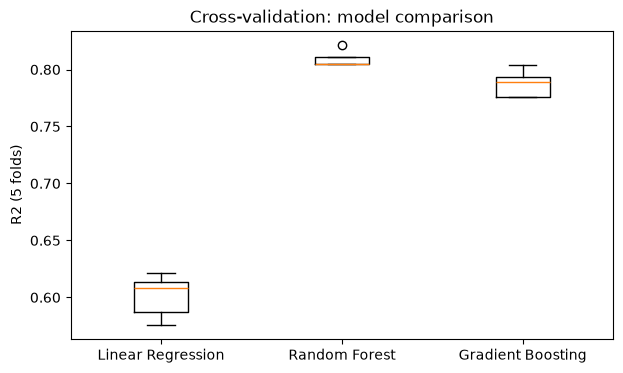

In [10]:
plt.figure(figsize=(7, 4))
plt.boxplot(list(cv_results.values()))
plt.xticks([1, 2, 3], list(cv_results.keys()))
plt.ylabel("R2 (5 folds)")
plt.title("Cross-validation: model comparison")
plt.show()

7. Predicted vs actual for the best model

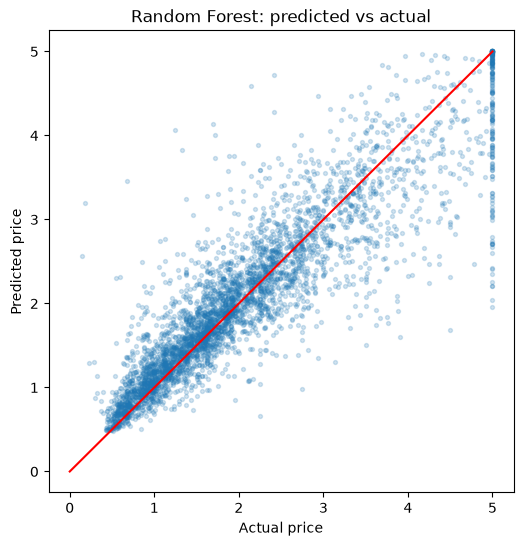

Negative predictions: 0  Max prediction: 5.0


In [11]:
best = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
best.fit(X_train, y_train)
pred = best.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.2, s=8)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Random Forest: predicted vs actual")
plt.show()
print("Negative predictions:", (pred < 0).sum(), " Max prediction:", pred.max().round(2))